| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_3_Interpolacion.ipynb) | [⏩](../6_ANALISIS_NUMERICO/6_5_Diferenciacion_numerica.ipynb) |

# 6.4 Integración numérica: del área a observables científicos

La energía de una señal, la masa de una densidad y una pérdida integral de una PINN requieren calcular integrales. La antiderivada puede no existir en forma elemental o la función puede conocerse solo en datos discretos. Estudiaremos cuadraturas deterministas, estimación del error y Monte Carlo con ejemplos reproducibles.

Objetivos: derivar trapecio y Simpson, medir sus órdenes, usar Gauss y cuadratura adaptativa, reconocer singularidades y construir una norma $L^2$. Requisitos: integral definida, derivadas y nociones de probabilidad.

## 1. Qué aproximamos y con qué información

Queremos
$$I=\int_a^b f(x)\,dx\approx Q=\sum_{i=1}^m w_i f(x_i).$$
Los nodos $x_i$ dicen dónde evaluar y los pesos $w_i$ qué aporte asignar. Si poseemos una función evaluable, podemos escoger nodos nuevos; si solo tenemos datos de sensores, debemos usar los puntos disponibles. Esta distinción determina qué algoritmos son posibles.

La integral tiene unidades de $f$ multiplicadas por unidades de $x$. Por ejemplo, integrar potencia en vatios respecto al tiempo en segundos produce energía en julios. Una media temporal requiere además dividir por la duración. La suma de muestras sin pesos no suele representar la magnitud física correcta.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate, integrate
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True,
                     "font.size": 11})
np.set_printoptions(precision=5, suppress=True)

## 2. Rectángulos y punto medio

Para intervalos uniformes de ancho $h=(b-a)/n$, la regla izquierda es
$$Q_L=h\sum_{i=0}^{n-1}f(a+ih).$$
Su error global típico es $O(h)$. El punto medio usa
$$Q_M=h\sum_{i=0}^{n-1}f(a+(i+1/2)h),$$
y por simetría cancela el término impar de Taylor: para $f\in C^2$, $I-Q_M=(b-a)h^2 f''(\xi)/24$. La palabra global indica la suma del error de todos los paneles; el error de un solo panel de punto medio es $O(h^3)$.

Para visualizar la geometría integraremos $e^{-x^2}$, cuya antiderivada se relaciona con una función especial.

Izquierda: 1.0044143364710418
Punto medio: 0.882268699199421
Referencia quad: 0.8820813907624215


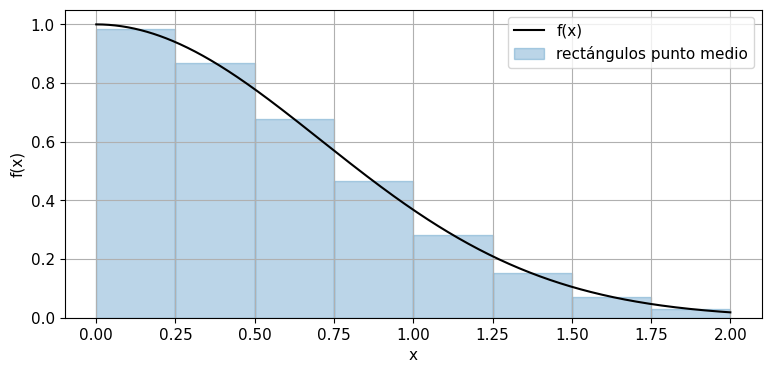

In [2]:
f = lambda x: np.exp(-x*x)
a, b, n = 0., 2., 8
edges = np.linspace(a, b, n+1); h = (b-a)/n
mid = (edges[:-1]+edges[1:])/2
q = np.linspace(a, b, 500)
plt.plot(q, f(q), "k", label="f(x)")
plt.bar(mid, f(mid), width=h, alpha=0.3, edgecolor="tab:blue", label="rectángulos punto medio")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.legend(); plt.show()
reference, estimated_error = integrate.quad(f, a, b)
print("Izquierda:", h*f(edges[:-1]).sum())
print("Punto medio:", h*f(mid).sum())
print("Referencia quad:", reference)

**Cómo interpretar el resultado.** La regla izquierda sobreestima una función decreciente como esta. En punto medio, errores positivos y negativos de cada rectángulo se compensan parcialmente. `quad` será una referencia de alta precisión para el experimento, pero su estimación de error sigue siendo una estimación numérica.

## 3. Trapecio como integral de un interpolante

Interpolar linealmente en $[x_i,x_{i+1}]$ e integrar esa recta produce
$$Q_{T,i}=\frac{h_i}{2}(f_i+f_{i+1}).$$
En malla uniforme,
$$Q_T=h\left[\frac{f_0+f_n}{2}+\sum_{i=1}^{n-1}f_i\right].$$
Para $f\in C^2$, $I-Q_T=-(b-a)h^2 f''(\xi)/12$. Si $f$ es convexa, los segmentos quedan encima y el trapecio sobreestima. En mallas no uniformes todavía puede sumarse cada trapecio, aunque la fórmula con un único $h$ ya no se aplica.

`scipy.integrate.trapezoid(y,x=x)` integra datos en el orden recibido: hay que ordenar correctamente la coordenada salvo que se busque una integral paramétrica orientada.

Trapecio: 0.34 Exacta: 0.3333333333333333 Error: 0.00666666666666671


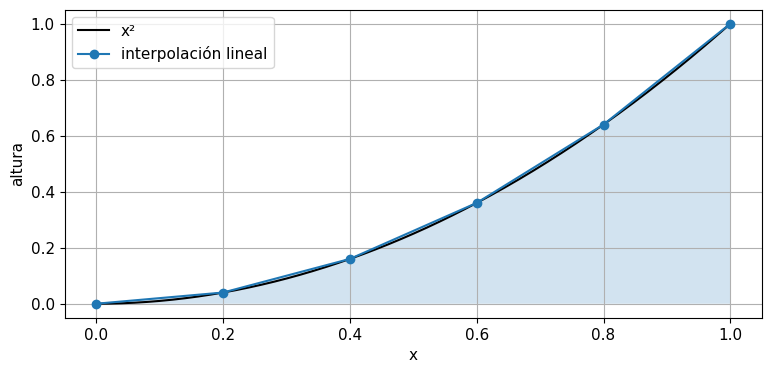

In [3]:
x = np.linspace(0, 1, 6); y = x*x
q = np.linspace(0, 1, 400)
plt.plot(q, q*q, "k", label="x²")
plt.plot(x, y, "o-", label="interpolación lineal")
plt.fill_between(x, y, alpha=0.2)
plt.xlabel("x"); plt.ylabel("altura"); plt.legend(); plt.show()
qt = integrate.trapezoid(y, x=x)
print("Trapecio:", qt, "Exacta:", 1/3, "Error:", qt-1/3)

**Cómo interpretar el resultado.** El signo positivo del error coincide con la convexidad de $x^2$. El resultado exacto sirve para verificar la implementación sin depender de otra cuadratura. Una integral puede aproximarse bien aunque el interpolante todavía muestre diferencias visibles.

## 4. Simpson y exactitud algebraica

Integramos una parábola por tres puntos equidistantes:
$$\int_{x_0}^{x_2}f(x)\,dx\approx\frac{h}{3}(f_0+4f_1+f_2).$$
La regla compuesta requiere un número par $n$ de subintervalos:
$$Q_S=\frac{h}{3}\left[f_0+f_n+4\sum_{i\;\text{impar}}f_i+2\sum_{i\;\text{par},\;0<i<n}f_i\right].$$
Es exacta para polinomios de grado hasta tres en malla uniforme, aunque su construcción usa parábolas; la simetría explica esa cancelación extra. Con $f\in C^4$, $I-Q_S=-(b-a)h^4f^{(4)}(\xi)/180$. Para nodos no uniformes la exactitud y los pesos cambian.

Definimos la regla explícitamente para entender los pesos antes de utilizar la biblioteca.

In [4]:
def simpson_uniform(fun, a, b, n):
    if n % 2 or n < 2:
        raise ValueError("n debe ser par y al menos 2")
    x = np.linspace(a, b, n+1); y = fun(x); h = (b-a)/n
    return h/3*(y[0]+y[-1]+4*y[1:-1:2].sum()+2*y[2:-1:2].sum())

for degree in range(5):
    fun = lambda z, degree=degree: z**degree
    value = simpson_uniform(fun, 0, 1, 4)
    print(f"grado={degree}, error={value-1/(degree+1):.3e}")
x = np.linspace(0, 2, 17)
print("Simpson propio:", simpson_uniform(f, 0, 2, 16))
print("Simpson SciPy:", integrate.simpson(f(x), x=x))

grado=0, error=0.000e+00
grado=1, error=0.000e+00
grado=2, error=0.000e+00
grado=3, error=0.000e+00
grado=4, error=5.208e-04
Simpson propio: 0.8820803965769919
Simpson SciPy: 0.8820803965769917


**Cómo interpretar el resultado.** Los errores hasta grado tres deben quedar cerca del redondeo; el de grado cuatro es no nulo. Que dos implementaciones coincidan verifica pesos e índices, mientras que comparar con integrales exactas verifica además la fórmula matemática.

## 5. Convergencia y extrapolación de Richardson

Si $Q(h)=I+C h^p+O(h^{p+1})$, podemos cancelar el término dominante:
$$Q_R=\frac{2^p Q(h/2)-Q(h)}{2^p-1}.$$
Para trapecio $p=2$, el denominador es tres. Esto no elimina errores de ruido ni singularidades que invaliden la expansión. El orden observado se mide con errores verdaderos cuando hay referencia; en problemas reales puede estimarse comparando sucesivos refinamientos, siempre que se esté en régimen asintótico.

trapecio órdenes: [1.98865 1.99718 1.9993  1.99982]
Simpson órdenes: [3.99758 4.00048 4.00018 4.00005]
Richardson órdenes: [4.00048 4.00018 4.00005 4.00003]


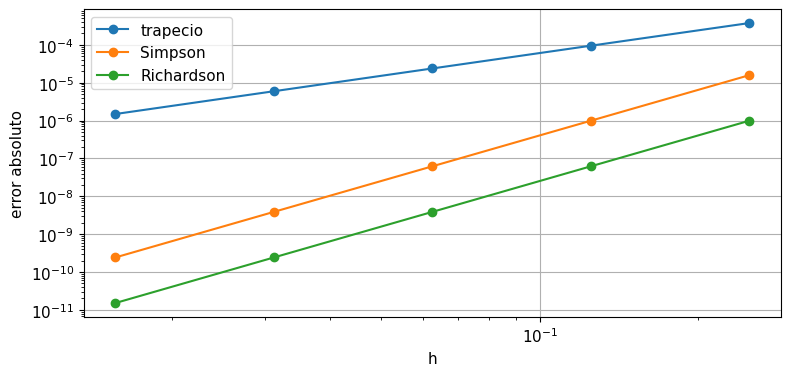

In [5]:
ns = np.array([8, 16, 32, 64, 128])
et, es, er = [], [], []
for n in ns:
    x = np.linspace(0, 2, n+1); xf = np.linspace(0, 2, 2*n+1)
    t = integrate.trapezoid(f(x), x=x)
    tf = integrate.trapezoid(f(xf), x=xf)
    et.append(abs(t-reference)); es.append(abs(simpson_uniform(f,0,2,n)-reference))
    er.append(abs((4*tf-t)/3-reference))
for label, values in [("trapecio",et),("Simpson",es),("Richardson",er)]:
    plt.loglog(2/ns, np.maximum(values,1e-16), "o-", label=label)
    print(label, "órdenes:", np.log2(np.array(values[:-1])/np.array(values[1:])))
plt.xlabel("h"); plt.ylabel("error absoluto"); plt.legend(); plt.show()

**Cómo interpretar el resultado.** Se esperan pendientes cercanas a dos y cuatro, respectivamente. La extrapolación del trapecio utiliza más evaluaciones que el trapecio grueso: comparar solo el número de paneles puede ocultar el coste adicional. Cerca de precisión de máquina las tasas dejan de ser fiables.

## 6. Cuadratura de Gauss-Legendre

La cuadratura de Gauss elige nodos y pesos para integrar exactamente muchos polinomios. Con $m$ nodos de Gauss-Legendre se alcanza grado $2m-1$. Los nodos son raíces del polinomio de Legendre de grado $m$ en $[-1,1]$.

Para trasladarlos a $[a,b]$, usa $x=(b-a)\xi/2+(a+b)/2$ y multiplica los pesos por $(b-a)/2$. Ese factor es el jacobiano del cambio de variable; olvidarlo da una respuesta con escala equivocada. La regla es muy eficiente para funciones suaves, pero requiere poder evaluar en sus propios nodos.

m= 2: integral=0.919486116641, error=3.740e-02
m= 4: integral=0.882229095933, error=1.477e-04
m= 8: integral=0.882081390420, error=3.425e-10
m=16: integral=0.882081390762, error=1.110e-16


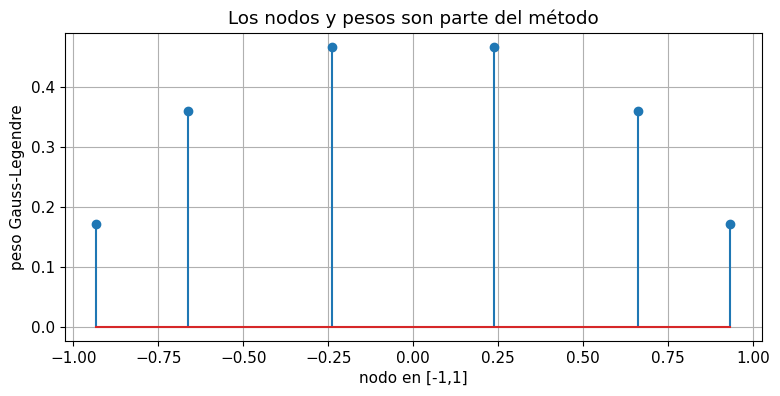

In [6]:
from numpy.polynomial.legendre import leggauss
def gauss(fun, a, b, m):
    xi, wi = leggauss(m)
    x = (b-a)*xi/2+(a+b)/2
    return (b-a)/2*np.dot(wi, fun(x))

for m in [2, 4, 8, 16]:
    qg = gauss(f, 0, 2, m)
    print(f"m={m:2d}: integral={qg:.12f}, error={abs(qg-reference):.3e}")
xi, wi = leggauss(6)
plt.stem(xi, wi)
plt.xlabel("nodo en [-1,1]"); plt.ylabel("peso Gauss-Legendre")
plt.title("Los nodos y pesos son parte del método"); plt.show()

**Cómo interpretar el resultado.** Para esta función analítica, pocos nodos dan gran precisión. Los pesos no son todos iguales. Este éxito no debe extrapolarse a una función con discontinuidades sin partir el dominio o aumentar resolución donde haga falta.

## 7. Adaptatividad y singularidades integrables

Una cuadratura adaptativa estima error local y subdivide donde detecta dificultad. `quad` permite tolerancias absoluta y relativa, pero no garantiza una cota rigurosa para cualquier función adversaria. Una discontinuidad conocida debe indicarse con `points` o separar la integral.

La función $1/\sqrt{x}$ tiene integral finita en $[0,1]$, pero valor infinito en cero. Evaluar una regla con ese extremo produce problemas. El cambio $x=s^2$, $dx=2s\,ds$, transforma la integral en $\int_0^1 2\,ds=2$ y elimina la singularidad. La regularidad del integrando transformado puede ser más valiosa que subir el orden de una regla.

In [7]:
singular_value, singular_est = integrate.quad(lambda x: 1/np.sqrt(x), 0, 1,
                                             epsabs=1e-10, epsrel=1e-10)
transformed = gauss(lambda s: np.full_like(s, 2.), 0, 1, 4)
print("Quad singular:", singular_value, "estimación:", singular_est)
print("Cambio x=s²:", transformed)
print("Error real quad:", abs(singular_value-2))

Quad singular: 1.9999999999999984 estimación: 5.773159728050814e-15
Cambio x=s²: 1.9999999999999998
Error real quad: 1.5543122344752192e-15


**Cómo interpretar el resultado.** La estimación interna y el error real no son idénticos. El resultado transformado es exacto para aritmética ideal porque el integrando es constante. No se evalúa la fórmula original en cero, evitando una operación inválida innecesaria.

## 8. Monte Carlo para integrales

Si $X\sim U(a,b)$,
$$I=(b-a)\mathbb E[f(X)],\qquad
\widehat I_N=\frac{b-a}{N}\sum_{i=1}^N f(X_i).$$
Para muestras independientes con varianza finita, el error estándar es $(b-a)s_f/\sqrt N$. Esa escala es probabilística; una realización puede tener error menor o mayor. El ritmo $N^{-1/2}$ es más lento que muchas cuadraturas 1D, pero no empeora su exponente con la dimensión. Esto lo hace útil en integrales de alta dimensión y pérdidas muestreadas.

La semilla permite reproducir el experimento. No mejora la precisión ni convierte un intervalo de confianza en una garantía determinista.

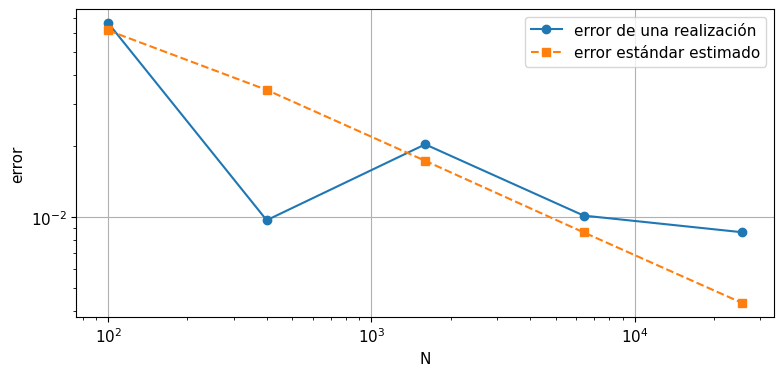

In [8]:
rng = np.random.default_rng(2026)
sizes = np.array([100, 400, 1600, 6400, 25600])
real_error, standard_error = [], []
for size in sizes:
    samples = rng.uniform(0, 2, size)
    values = f(samples)
    estimate = 2*values.mean()
    se = 2*values.std(ddof=1)/np.sqrt(size)
    real_error.append(abs(estimate-reference)); standard_error.append(se)
plt.loglog(sizes, real_error, "o-", label="error de una realización")
plt.loglog(sizes, standard_error, "s--", label="error estándar estimado")
plt.xlabel("N"); plt.ylabel("error"); plt.legend(); plt.show()

**Cómo interpretar el resultado.** El error verdadero oscila y no necesita disminuir en cada incremento de tamaño. El error estándar describe incertidumbre típica y sigue una tendencia más regular. Para evaluar cobertura de intervalos, repite todo el muestreo con múltiples semillas independientes.

## 9. Una pérdida integral en SciML

Una norma física frecuente es
$$\|u-\widehat u\|_{L^2}^2=\int_\Omega (u(x)-\widehat u(x))^2\,dx.$$
Un promedio simple de muestras uniformes aproxima la integral dividida por el volumen del dominio. Con malla no uniforme, tratar todos los nodos como equivalentes sesga el resultado hacia regiones densamente muestreadas. Si se entrena un residual de PDE con muestreo adaptativo, la distribución del muestreo también cambia la pérdida a menos que se corrijan pesos.

Tomaremos $u=\sin(\pi x)$ y una perturbación $0.1\sin(2\pi x)$: su norma al cuadrado exacta es $0.01/2=0.005$.

In [9]:
x = np.linspace(0, 1, 101)**2  # más nodos cerca de cero
u = np.sin(np.pi*x); predicted = u+0.1*np.sin(2*np.pi*x)
loss = integrate.trapezoid((u-predicted)**2, x=x)
naive = np.mean((u-predicted)**2)
print("Integral con pesos:", loss)
print("Promedio de nodos no uniformes:", naive)
print("Valor exacto:", 0.005)

Integral con pesos: 0.0049999994716362845
Promedio de nodos no uniformes: 0.004083029449713559
Valor exacto: 0.005


**Cómo interpretar el resultado.** La cuadratura pondera longitud de intervalos, mientras que el promedio pondera frecuencia de nodos. El significado científico de una métrica depende de su medida, no solo de elevar errores al cuadrado.

## 10. Protocolo y errores habituales

Primero define dominio, unidades y si puedes obtener nuevas evaluaciones. Después busca discontinuidades, oscilaciones o extremos singulares. Usa una regla compatible con esa información y realiza refinamiento. Compara el error contra el coste, medido en evaluaciones de la función, no únicamente en tamaño de arreglo.

No confundas la integral de $f$ con la de $|f|$ o $f^2$: errores positivos y negativos pueden cancelarse en la primera. No apliques Simpson uniforme con un número impar de paneles usando los mismos pesos. En datos ruidosos, añadir muestras puede reducir incertidumbre estadística, pero no elimina sesgo de calibración. Aumentar precisión de cuadratura más allá de la exactitud de los datos puede ser un gasto sin valor científico.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_3_Interpolacion.ipynb) | [⏩](../6_ANALISIS_NUMERICO/6_5_Diferenciacion_numerica.ipynb) |